# Pronóstico de ventas por SKU
## Parte 2: baselines simples

Naive, Seasonal Naive, media histórica y medias móviles de 3, 6 y 12 meses. Son la referencia a superar.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Carga de datos

In [4]:
skus = ["A", "B", "C", "D", "E"]

datos = []
for s in skus:
    datos.append(pd.read_excel(f"Datos/ventas_SKU_P{s}_hasta_mayo.xlsx"))

df = pd.concat(datos)
df["SKU"] = df["SKU"].str.replace("Producto", "")
ventas = df.pivot(index="Fecha", columns="SKU", values="VentasMensuales")
ventas.tail()

SKU,A,B,C,D,E
Fecha,,,,,
2025-01-01,45,63,22,30,169
2025-02-01,33,49,16,59,160
2025-03-01,23,42,16,25,130
2025-04-01,42,61,27,66,139
2025-05-01,32,53,29,65,116


## Esquema de evaluación

Walk-forward con ventana creciente. 
En cada corte entreno con todo lo disponible hasta ese mes, pronostico los 3 meses siguientes y comparo con lo vendido. Después avanzo un mes.

- 15 cortes, de diciembre 2023 a febrero 2025.
- Horizontes 1, 2 y 3 meses.
- Error = pronóstico − real. Sesgo positivo significa que el modelo sobreestima.
- MASE: error absoluto dividido por el error promedio de repetir el mes anterior dentro del entrenamiento. Menor a 1 es mejor que esa referencia.

In [5]:
cortes = pd.date_range("2023-12-01", "2025-02-01", freq="MS")
horizonte = 3

print("Cantidad de cortes:", len(cortes))
print("Primer corte:", cortes[0].strftime("%Y-%m"), "| Último corte:", cortes[-1].strftime("%Y-%m"))

Cantidad de cortes: 15
Primer corte: 2023-12 | Último corte: 2025-02


## Modelos

- Naive: el próximo mes es igual al último observado.
- Seasonal Naive: el próximo mes es igual al mismo mes del año anterior.
- Media: el promedio de toda la historia disponible.
- Media móvil: el promedio de los últimos 3, 6 o 12 meses.

In [6]:
def naive(train, h):
    return [train.iloc[-1]] * h

def seasonal_naive(train, h):
    return [train.iloc[-12 + i] for i in range(h)]

def media(train, h):
    return [train.mean()] * h

def media_movil(train, h, k):
    return [train.iloc[-k:].mean()] * h

modelos = {
    "Naive": naive,
    "Seasonal Naive": seasonal_naive,
    "Media": media,
    "Media M3": lambda train, h: media_movil(train, h, 3),
    "Media M6": lambda train, h: media_movil(train, h, 6),
    "Media M12": lambda train, h: media_movil(train, h, 12),
}

## Walk-forward

In [7]:
filas = []

for s in skus:
    for corte in cortes:
        train = ventas.loc[:corte, s]
        real = ventas.loc[corte:, s].iloc[1:horizonte + 1]
        escala = train.diff().abs().mean()

        for nombre, modelo in modelos.items():
            pronostico = modelo(train, horizonte)
            for i in range(horizonte):
                filas.append({
                    "SKU": s,
                    "Modelo": nombre,
                    "Corte": corte,
                    "Horizonte": i + 1,
                    "Real": real.iloc[i],
                    "Fecha": real.index[i],
                    "Pronostico": pronostico[i],
                    "Escala": escala,
                })

resultados = pd.DataFrame(filas)
resultados["Error"] = resultados["Pronostico"] - resultados["Real"]
resultados["ErrorAbs"] = resultados["Error"].abs()
resultados.head()

,SKU,Modelo,Corte,Horizonte,Real,Fecha,Pronostico,Escala,Error,ErrorAbs
0,A,Naive,2023-12-01,1,37,2024-01-01,30.0,15.942857,-7.0,7.0
1,A,Naive,2023-12-01,2,23,2024-02-01,30.0,15.942857,7.0,7.0
2,A,Naive,2023-12-01,3,19,2024-03-01,30.0,15.942857,11.0,11.0
3,A,Seasonal Naive,2023-12-01,1,37,2024-01-01,34.0,15.942857,-3.0,3.0
4,A,Seasonal Naive,2023-12-01,2,23,2024-02-01,13.0,15.942857,-10.0,10.0


In [8]:
def metricas(g):
    return pd.Series({
        "MAE": g["ErrorAbs"].mean(),
        "RMSE": np.sqrt((g["Error"] ** 2).mean()),
        "MASE": (g["ErrorAbs"] / g["Escala"]).mean(),
        "Sesgo": g["Error"].mean(),
    })

## Resultados por SKU

In [9]:
tabla = resultados.groupby(["SKU", "Modelo"]).apply(metricas)
tabla.round(2)

MAE   RMSE  MASE  Sesgo
SKU Modelo                                   
A   Media           13.29  15.01  0.90   3.35
    Media M12       14.78  16.32  1.00   1.17
    Media M3        14.22  17.29  0.97   0.93
    Media M6        17.82  19.76  1.21   1.16
    Naive           11.91  15.32  0.82   0.04
    Seasonal Naive  13.36  16.82  0.91   0.38
B   Media           24.18  33.35  1.08 -21.87
    Media M12       21.07  29.32  0.95 -12.05
    Media M3        21.85  29.03  0.98  -3.87
    Media M6        21.21  28.43  0.95  -7.11
    Naive           29.24  36.47  1.31  -2.27
    Seasonal Naive  31.89  38.92  1.43 -19.22
C   Media            6.93   8.09  0.85   2.01
    Media M12        7.30   8.80  0.90   1.59
    Media M3         8.07   9.90  0.99   0.16
    Media M6         7.50   9.29  0.92   0.58
    Naive            9.24  11.18  1.14  -0.98
    Seasonal Naive   9.09  12.15  1.12   2.82
D   Media           25.11  31.81  0.83   3.09
    Media M12       29.06  35.89  0.96  14.36
    Media M3        25.28  30.21  0.84  12.69
    Media M6        26.17  32.02  0.87  17.20
    Naive           31.98  38.06  1.06   6.56
    Seasonal Naive  48.22  61.84  1.60   7.82
E   Media           43.32  51.72  2.01 -41.78
    Media M12       23.44  29.43  1.09  -7.87
    Media M3        30.45  36.61  1.41  -0.20
    Media M6        37.94  43.97  1.76   2.03
    Naive           27.40  32.28  1.27  -0.78
    Seasonal Naive  33.53  40.02  1.56 -25.22

In [10]:
tabla["MASE"].unstack().round(2)

Modelo,Media,Media M12,Media M3,Media M6,Naive,Seasonal Naive
SKU,,,,,,
A,0.90,1.00,0.97,1.21,0.82,0.91
B,1.08,0.95,0.98,0.95,1.31,1.43
C,0.85,0.90,0.99,0.92,1.14,1.12
D,0.83,0.96,0.84,0.87,1.06,1.60
E,2.01,1.09,1.41,1.76,1.27,1.56


- El Seasonal Naive no es el mejor en ningún SKU, ni siquiera en A y E. Confirma lo del EDA: el patrón mes a mes no se repite y copiar el mismo mes del año anterior es copiar ruido.
- La media gana en B, C y D. En C y D tiene sesgo bajo. En B gana con un sesgo de −22 unidades: subestima porque mezcla los meses anteriores y posteriores al salto de mayo 2024. Gana solo porque el Naive es demasiado ruidoso.
- En E la media es el peor (sesgo de −42) por el salto de julio 2023. El Naive es el mejor.
- En A, Naive y media quedan cerca.

Medias móviles:
- B: la media móvil de 12 meses baja el MASE de 1.08 (media) a 0.95. La de 3 meses reduce el sesgo de −22 a −4, porque se olvida rápido del nivel anterior al salto.
- E: la media móvil de 12 meses es la mejor (1.09) y le gana al Naive (1.27). Una ventana de 12 meses cubre el año completo, así que el semestre alto y el bajo se compensan.
- Por la misma razón, la de 6 meses es la peor en A (1.21) y en E (1.76): siempre promedia un solo semestre y llega tarde al cambio de estación.
- En C la media sigue siendo la mejor (0.85). Con una serie sin cambios de nivel, más historia es mejor.
- En D la media (0.83) y la media móvil de 3 meses (0.84) empatan. Las medias móviles sobreestiman entre 13 y 17 unidades porque la serie viene cayendo y llegan tarde. La media tiene sesgo bajo, pero en parte porque arrastra el período bajo de 2022-2023.

## Resultados por horizonte

In [11]:
por_horizonte = resultados.groupby(["SKU", "Modelo", "Horizonte"]).apply(metricas)
por_horizonte["MASE"].unstack().round(2)

Horizonte              1     2     3
SKU Modelo                          
A   Media           0.92  0.90  0.86
    Media M12       1.05  1.02  0.93
    Media M3        0.79  0.97  1.15
    Media M6        1.07  1.23  1.32
    Naive           0.61  0.89  0.95
    Seasonal Naive  0.86  0.95  0.92
B   Media           1.03  1.08  1.13
    Media M12       0.98  0.93  0.93
    Media M3        1.08  0.94  0.91
    Media M6        0.97  0.93  0.95
    Naive           1.29  1.42  1.21
    Seasonal Naive  1.44  1.41  1.44
C   Media           0.85  0.88  0.84
    Media M12       0.91  0.91  0.87
    Media M3        0.92  1.05  1.01
    Media M6        0.87  0.95  0.94
    Naive           1.08  1.18  1.16
    Seasonal Naive  1.06  1.12  1.19
D   Media           0.83  0.85  0.82
    Media M12       0.94  0.97  0.97
    Media M3        0.93  0.82  0.77
    Media M6        0.90  0.85  0.86
    Naive           1.17  0.91  1.11
    Seasonal Naive  1.60  1.59  1.61
E   Media           2.01  2.00  2.02
    Media M12       1.09  1.06  1.11
    Media M3        1.09  1.40  1.76
    Media M6        1.58  1.84  1.88
    Naive           1.12  1.18  1.51
    Seasonal Naive  1.63  1.50  1.54

- A Naive es el mejor para pronosticos a un mes. Pero a medida que avanzamos pierde ventaja y se asemeja a Media.
- B se confirma que va a ser difícil de pronosticar con métodos simples.
- C Media es el mejor y tiene resultados estables. Puede ser que con la información de ventas promedio se puedan hacer buenos pronosticos.
- D Media es el mejor y es estable.
- E Naive es el mejor pero para horizontes de 3 meses el error aumenta mucho.

Objetivo:
- A -> mejorar Naive en horizontes largos
- B -> adaptarnos al cambio de nivel
- C -> intentar mejorar una media más sólida
- D -> que pueda adpatarse a cambios reicnetes
- E -> aprovechar la presistencia temporal

Medias móviles por horizonte:
- En E la media móvil de 12 meses se mantiene estable (1.09, 1.06 y 1.11), mientras el Naive sube a 1.51 a 3 meses.
- En D la media móvil de 3 meses mejora con el horizonte (0.93, 0.82 y 0.77).

## Pronóstico a 1 mes contra lo real

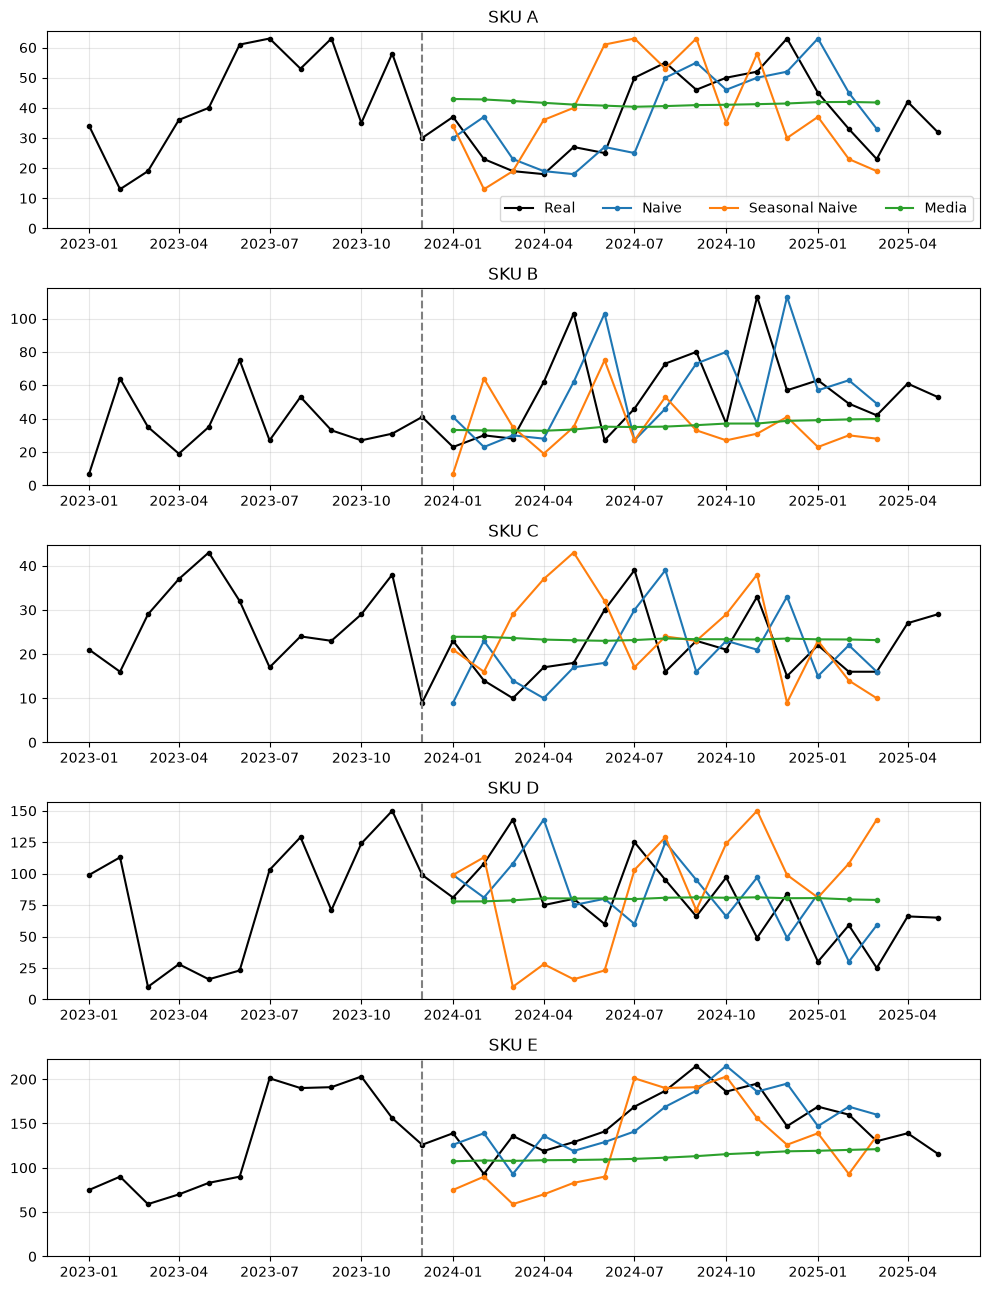

In [12]:
fig, axes = plt.subplots(5, 1, figsize=(10, 13))
un_mes = resultados[resultados["Horizonte"] == 1]

for i, s in enumerate(skus):
    axes[i].plot(ventas.loc["2023-01-01":, s], color="black", marker="o", markersize=3, label="Real")
    for nombre in ["Naive", "Seasonal Naive", "Media"]:
        p = un_mes[(un_mes["SKU"] == s) & (un_mes["Modelo"] == nombre)]
        axes[i].plot(p["Fecha"], p["Pronostico"], marker="o", markersize=3, label=nombre)
    axes[i].axvline(cortes[0], color="gray", linestyle="--")
    axes[i].set_title(f"SKU {s}")
    axes[i].set_ylim(bottom=0)
    axes[i].grid(alpha=0.3)

axes[0].legend(ncol=4)
plt.tight_layout()
plt.show()

- El Naive sigue a la serie con un mes de retraso: acierta cuando la serie es persistente y falla cuando salta mes a mes.
- En E la media queda por debajo de lo real casi todo el período, y en B desde mayo 2024.
- En D el Seasonal Naive copia el período anómalo de 2022-2023 y pronostica pocas unidades entre marzo y junio 2024.
- En D la media queda cerca de 80 mientras las ventas de los últimos meses están entre 25 y 66. Hacia el final sobreestima.

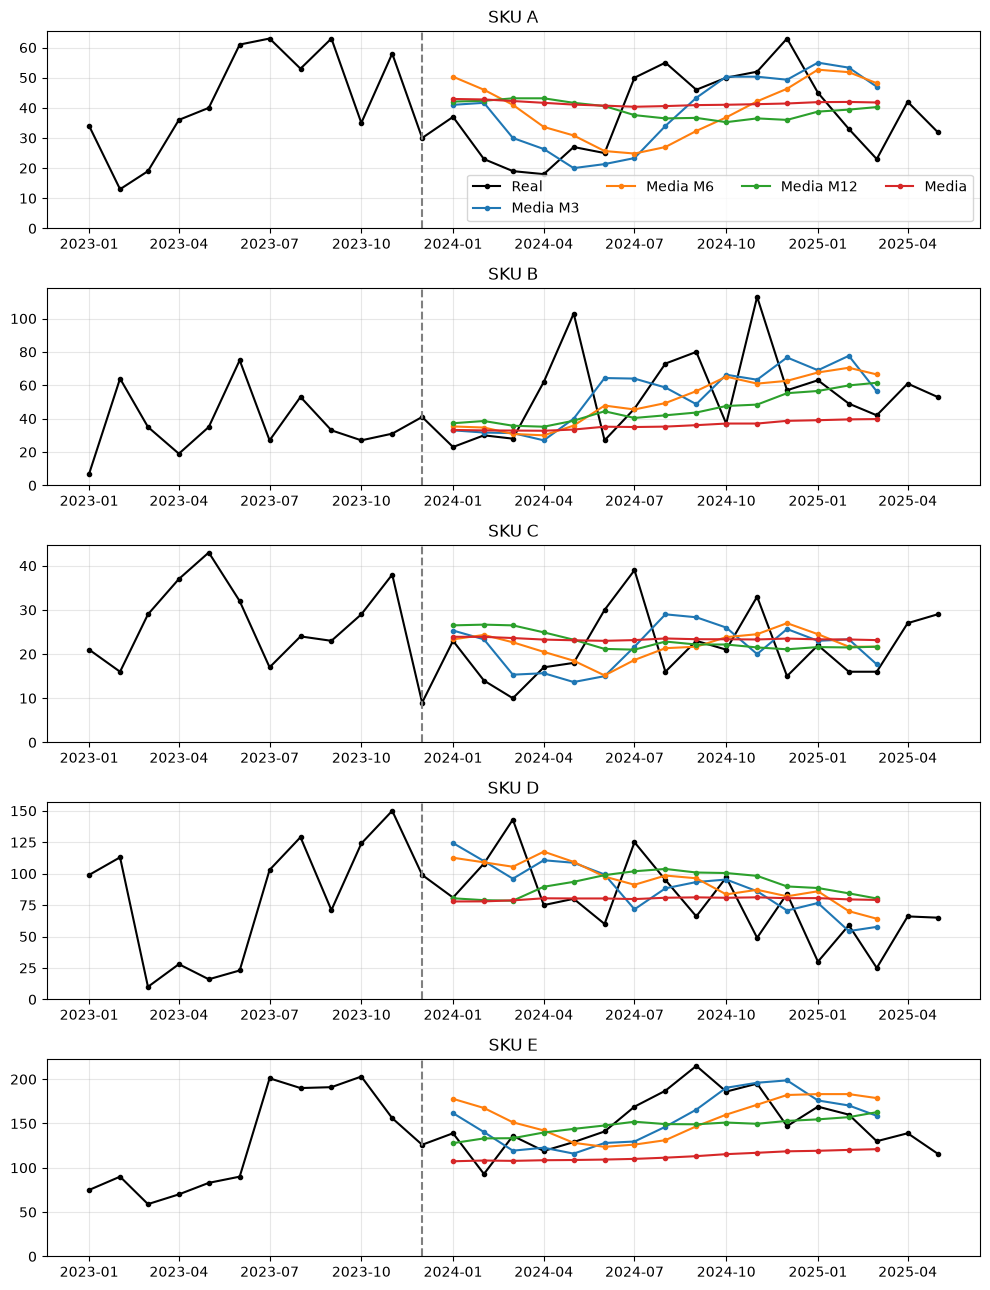

In [17]:
fig, axes = plt.subplots(5, 1, figsize=(10, 13))

for i, s in enumerate(skus):
    axes[i].plot(ventas.loc["2023-01-01":, s], color="black", marker="o", markersize=3, label="Real")
    for nombre in ["Media M3", "Media M6", "Media M12", "Media"]:
        p = un_mes[(un_mes["SKU"] == s) & (un_mes["Modelo"] == nombre)]
        axes[i].plot(p["Fecha"], p["Pronostico"], marker="o", markersize=3, label=nombre)
    axes[i].axvline(cortes[0], color="gray", linestyle="--")
    axes[i].set_title(f"SKU {s}")
    axes[i].set_ylim(bottom=0)
    axes[i].grid(alpha=0.3)

axes[0].legend(ncol=4)
plt.tight_layout()
plt.show()

## Baseline a superar por SKU

In [14]:
mase = tabla["MASE"].unstack()
mejor = pd.DataFrame({
    "Mejor baseline": mase.idxmin(axis=1),
    "MASE": mase.min(axis=1),
    "MAE": [tabla.loc[(s, mase.loc[s].idxmin()), "MAE"] for s in skus],
    "Sesgo": [tabla.loc[(s, mase.loc[s].idxmin()), "Sesgo"] for s in skus],
})
mejor.round(2)

,Mejor baseline,MASE,MAE,Sesgo
SKU,,,,
A,Naive,0.82,11.91,0.04
B,Media M12,0.95,21.07,-12.05
C,Media,0.85,6.93,2.01
D,Media,0.83,25.11,3.09
E,Media M12,1.09,23.44,-7.87


In [ ]:
# El baseline que deberíamos superar a horizonte 3

resultados_h3 = resultados[resultados["Horizonte"] == 3]
tabla = resultados_h3.groupby(["SKU", "Modelo"]).apply(metricas)

mase = tabla["MASE"].unstack()
mejor = pd.DataFrame({
    "Mejor baseline": mase.idxmin(axis=1),
    "MASE": mase.min(axis=1),
    "MAE": [tabla.loc[(s, mase.loc[s].idxmin()), "MAE"] for s in skus],
    "Sesgo": [tabla.loc[(s, mase.loc[s].idxmin()), "Sesgo"] for s in skus],
})

mejor.round(2)

,Mejor baseline,MASE,MAE,Sesgo
SKU,,,,
A,Media,0.86,12.86,2.84
B,Media M3,0.91,20.53,-5.73
C,Media,0.84,6.83,1.26
D,Media M3,0.77,23.29,14.93
E,Media M12,1.11,23.86,-8.89


## Pronóstico de referencia junio-agosto 2025

In [15]:
fechas = pd.date_range("2025-06-01", periods=3, freq="MS")

referencia = []
for s in skus:
    for nombre, modelo in modelos.items():
        referencia.append([s, nombre] + list(np.round(modelo(ventas[s], 3), 1)))

referencia = pd.DataFrame(referencia, columns=["SKU", "Modelo"] + [f.strftime("%Y-%m") for f in fechas])
referencia.set_index(["SKU", "Modelo"])

2025-06  2025-07  2025-08
SKU Modelo                                   
A   Naive              32.0     32.0     32.0
    Seasonal Naive     25.0     50.0     55.0
    Media              41.2     41.2     41.2
    Media M3           32.3     32.3     32.3
    Media M6           39.7     39.7     39.7
    Media M12          43.0     43.0     43.0
B   Naive              53.0     53.0     53.0
    Seasonal Naive     27.0     46.0     73.0
    Media              40.4     40.4     40.4
    Media M3           52.0     52.0     52.0
    Media M6           54.2     54.2     54.2
    Media M12          58.4     58.4     58.4
C   Naive              29.0     29.0     29.0
    Seasonal Naive     30.0     39.0     16.0
    Media              23.2     23.2     23.2
    Media M3           24.0     24.0     24.0
    Media M6           20.8     20.8     20.8
    Media M12          23.9     23.9     23.9
D   Naive              65.0     65.0     65.0
    Seasonal Naive     60.0    125.0     95.0
    Media              77.6     77.6     77.6
    Media M3           52.0     52.0     52.0
    Media M6           54.8     54.8     54.8
    Media M12          68.4     68.4     68.4
E   Naive             116.0    116.0    116.0
    Seasonal Naive    141.0    169.0    187.0
    Media             121.4    121.4    121.4
    Media M3          128.3    128.3    128.3
    Media M6          143.5    143.5    143.5
    Media M12         162.8    162.8    162.8

## Conclusiones

- Ningún baseline sirve para todos los SKUs: Naive para A, media para C y D, y media móvil de 12 meses para B y E.
- Las medias móviles resuelven en parte el cambio de nivel: en B y E reducen mucho el sesgo de la media. Igual quedan cerca de 1, así que hay margen para mejorar.
- Las ventanas de 6 meses no sirven en A y E, porque cortan la estacionalidad semestral a la mitad.
- El Seasonal Naive queda descartado como modelo, pero se mantiene como referencia.
- En D la media y la media móvil de 3 meses empatan. Para el pronóstico final hay que decidir si la caída reciente es un nuevo nivel: la media da 78 y la media móvil de 3 meses da 52.

Próximo paso: suavizado exponencial (simple, Holt y Holt-Winters). El simple es una media móvil que elige sola cuánto pesa cada mes, y Holt-Winters puede incorporar la estacionalidad de A y E.